In [ ]:
pip install mindspore

In [ ]:
import mindspore

In [ ]:
import numpy as np
from mindspore import tensor
from mindspore import dtype




In [ ]:
x=tensor(np.array([[1,2],[3,4]]),dtype.int32)
print(x)
x

[[1 2]
 [3 4]]


Tensor(shape=[2, 2], dtype=Int32, value=
[[1, 2],
 [3, 4]])

In [ ]:
from mindspore import ops
Oneslike=ops.OnesLike()
output=Oneslike(x)
output

Tensor(shape=[2, 2], dtype=Int32, value=
[[1, 1],
 [1, 1]])

In [ ]:
x=tensor(np.array([[1,2,5],[3,4,6],[0,1,0]]),dtype.int32)
x
output=Oneslike(x)
output

Tensor(shape=[3, 3], dtype=Int32, value=
[[1, 1, 1],
 [1, 1, 1],
 [1, 1, 1]])

In [ ]:
from mindspore.ops import operations as op

shape=(2,2)
ones=op.Ones()
z=ones(shape,dtype.int32)
print(z)

[[1 1]
 [1 1]]


In [ ]:
zeros=ops.Zeros()
k=zeros(shape)
print(k)

[[0. 0.]
 [0. 0.]]


In [ ]:
print(k.shape)
print(x.dtype)
print(x.ndim)
print(x.size)

(2, 2)
Int32
2
9


In [ ]:
y=tensor(np.array([[True,True],[False,True]]),dtype.bool_)
y

Tensor(shape=[2, 2], dtype=Bool, value=
[[ True,  True],
 [False,  True]])

In [ ]:
yarray=y.asnumpy()
yarray

array([[ True,  True],
       [False,  True]])

In [ ]:
print(x)

[[1 2 5]
 [3 4 6]
 [0 1 0]]


In [ ]:
print(x[0])

[1 2 5]


In [ ]:
print(x[:,0])

[1 3 0]


In [ ]:
print(x[...,-1])

[5 6 0]


In [ ]:
data1=tensor(np.array([[0,1],[2,3]]))
data2=tensor(np.array([[4,5],[6,7]]))

In [ ]:
myop=op.Stack()
out=myop(data1,data2)
print(out)

[[[0 1]
  [2 3]]

 [[4 5]
  [6 7]]]


In [ ]:
import os
import mindspore.dataset as ds
import matplotlib.pyplot as plt


3
8
2


<function matplotlib.pyplot.show(close=None, block=None)>

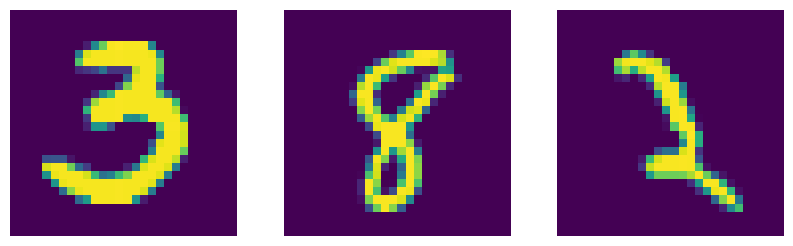

In [ ]:
datapath='/content/drive/MyDrive/traindataset/train'

# Read 3 images from MNIST Dataset
mnist_dataset=ds.MnistDataset(dataset_dir=datapath,num_samples=3)
#view the images and set the image sizes

plt.figure(figsize=(10,10))

i=1

for d in mnist_dataset.create_dict_iterator(output_numpy=True):
  plt.subplot(3,3,i)
  plt.imshow(d['image'][:,:,0])
  plt.axis('off')
  i +=1
  print(d['label'])

plt.show



In [ ]:
from mindspore.dataset.vision import Inter
import mindspore.dataset.vision.c_transforms as cvt


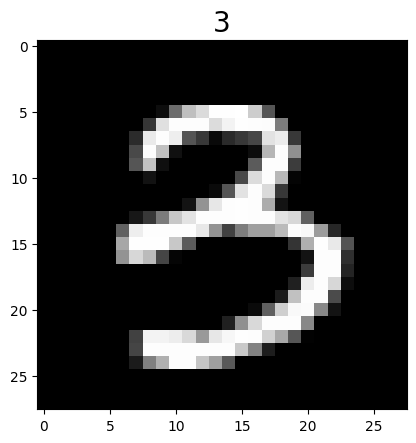

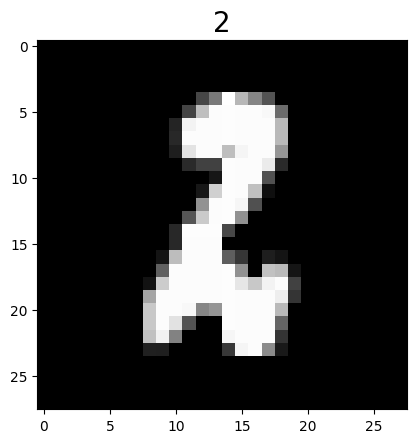

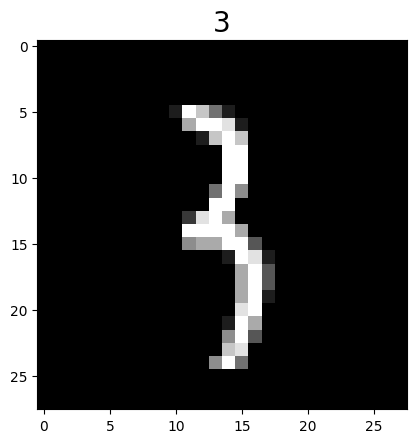

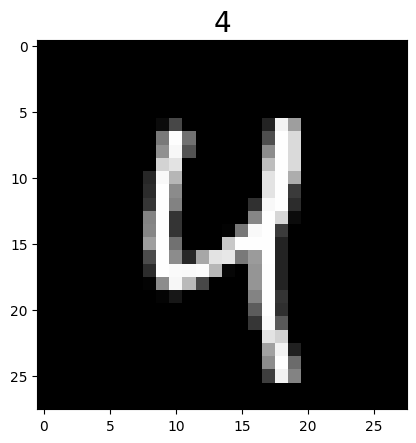

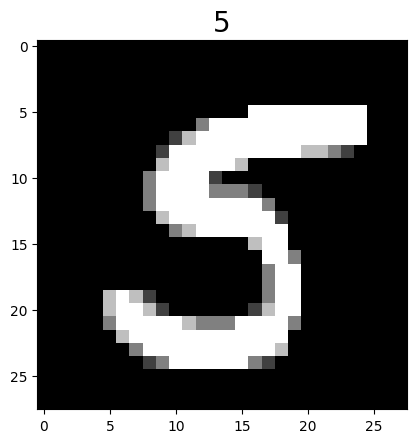

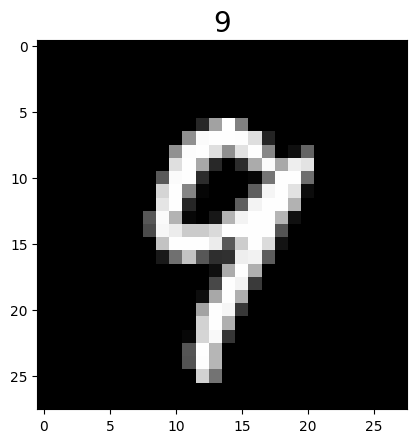

In [ ]:

mnist_dataset=ds.MnistDataset(dataset_dir=datapath,num_samples=6)
mnist_it=mnist_dataset.create_dict_iterator()
for i in range(6):
  data=next(mnist_it)
  plt.imshow(data['image'].asnumpy().squeeze(),cmap=plt.cm.gray)
  plt.title(data['label'].asnumpy(),fontsize=20)
  plt.show()

In [ ]:
import mindspore.nn as nn

class LeNet5(nn.Cell):
    """
    Lenet network structure
    """
    def __init__(self, num_class=10, num_channel=1):
        super(LeNet5, self).__init__()
        # Define the required operations.
        self.conv1 = nn.Conv2d(num_channel, 6, 5, pad_mode='valid')
        self.conv2 = nn.Conv2d(6, 16, 5, pad_mode='valid')
        self.fc1 = nn.Dense(16 * 4 * 4, 120)
        self.fc2 = nn.Dense(120, 84)
        self.fc3 = nn.Dense(84, num_class)
        self.relu = nn.ReLU()
        self.max_pool2d = nn.MaxPool2d(kernel_size=2, stride=2)
        self.flatten = nn.Flatten()

    def construct(self, x):
        # Use the defined operations to build a feedforward network.
        x = self.conv1(x)
        x = self.relu(x)
        x = self.max_pool2d(x)
        x = self.conv2(x)
        x = self.relu(x)
        x = self.max_pool2d(x)
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        return x



In [ ]:
model=LeNet5()

for m in model.parameters_and_names():
  print(m)

('conv1.weight', Parameter (name=conv1.weight, shape=(6, 1, 5, 5), dtype=Float32, requires_grad=True))
('conv2.weight', Parameter (name=conv2.weight, shape=(16, 6, 5, 5), dtype=Float32, requires_grad=True))
('fc1.weight', Parameter (name=fc1.weight, shape=(120, 256), dtype=Float32, requires_grad=True))
('fc1.bias', Parameter (name=fc1.bias, shape=(120,), dtype=Float32, requires_grad=True))
('fc2.weight', Parameter (name=fc2.weight, shape=(84, 120), dtype=Float32, requires_grad=True))
('fc2.bias', Parameter (name=fc2.bias, shape=(84,), dtype=Float32, requires_grad=True))
('fc3.weight', Parameter (name=fc3.weight, shape=(10, 84), dtype=Float32, requires_grad=True))
('fc3.bias', Parameter (name=fc3.bias, shape=(10,), dtype=Float32, requires_grad=True))


In [ ]:
from mindspore import Model
loss=nn.SoftmaxCrossEntropyWithLogits(sparse=True,reduction='mean')
opt=nn.Momentum(model.trainable_params(),learning_rate=0.01,momentum=0.9)

cnnmodel=Model(network=model,loss_fn=loss,optimizer=opt,metrics={'accuracy'})

In [ ]:
import mindspore as ms
import mindspore.dataset.transforms as C
import mindspore.dataset.vision as CV
from mindspore.train.callback import  LossMonitor

DATA_DIR = '/content/drive/MyDrive/mnist/MNIST/train'
mnist_dataset = ds.MnistDataset(DATA_DIR)

resize_op = CV.Resize((28,28))
rescale_op = CV.Rescale(1/255,0)
hwc2chw_op = CV.HWC2CHW()
mnist_dataset  = mnist_dataset .map(input_columns="image", operations=[rescale_op,resize_op, hwc2chw_op])
mnist_dataset  = mnist_dataset .map(input_columns="label", operations=C.TypeCast(ms.int32))
mnist_dataset = mnist_dataset.batch(32)
loss_cb = LossMonitor(per_print_times=10)
# dataset is an input parameter, which indicates the training set, and epoch indicates the number of training epochs of the training set.
cnnmodel.train(epoch=1, train_dataset=mnist_dataset,callbacks=[loss_cb])


epoch: 1 step: 10, loss is 2.307164430618286
epoch: 1 step: 20, loss is 2.3072850704193115
epoch: 1 step: 30, loss is 2.2965354919433594
epoch: 1 step: 40, loss is 2.3067569732666016
epoch: 1 step: 50, loss is 2.288813829421997
epoch: 1 step: 60, loss is 2.2984001636505127
epoch: 1 step: 70, loss is 2.2951650619506836
epoch: 1 step: 80, loss is 2.2629764080047607
epoch: 1 step: 90, loss is 2.2705819606781006
epoch: 1 step: 100, loss is 2.294464111328125
epoch: 1 step: 110, loss is 2.25907564163208
epoch: 1 step: 120, loss is 2.244328737258911
epoch: 1 step: 130, loss is 2.1622743606567383
epoch: 1 step: 140, loss is 2.0792534351348877
epoch: 1 step: 150, loss is 2.022702693939209
epoch: 1 step: 160, loss is 1.4255774021148682
epoch: 1 step: 170, loss is 1.085856318473816
epoch: 1 step: 180, loss is 1.2984191179275513
epoch: 1 step: 190, loss is 0.8110743165016174
epoch: 1 step: 200, loss is 1.1549440622329712
epoch: 1 step: 210, loss is 0.898309588432312
epoch: 1 step: 220, loss is 0.6